# 06 - Individual Model Training & Cross-Validation
## NASA C-MAPSS Turbofan RUL Prediction (FD001)

### Learning Objectives & Methodology
1. **Identical Cross-Validation**: Evaluate 3 individual regression baselines using the exact same 5-fold `GroupKFold` splits (partitioned by `unit_number` with zero engine overlap).
2. **Model-Specific Preprocessing**:
   - **Linear Regression**: `StandardScaler` fitted strictly on each training fold; validation fold transformed.
   - **Random Forest Regressor**: Original unscaled numerical features (200 estimators).
   - **XGBoost Regressor**: Original unscaled numerical features (300 estimators, learning rate 0.05, max depth 4).
3. **Out-of-Fold Diagnostics**:
   - Generate out-of-fold predictions covering all 20,631 records across all 100 engines.
   - Plot Actual vs. Predicted RUL and Residual Diagnostics.
   - Extract and compare feature importances and linear coefficients across folds.
4. **Comparative Benchmark**: Aggregate MAE, RMSE, and $R^2$ across all folds to evaluate model trade-offs.

*Strict ML Constraint: The NASA test set (`test_FD001.txt` and `RUL_FD001.txt`) is completely untouched.*

In [1]:
import sys
import json
from pathlib import Path

# Setup project root
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

from src.models.linear_regression_model import run_linear_regression_cv
from src.models.random_forest_model import run_random_forest_cv
from src.models.xgboost_model import run_xgboost_cv

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print(f"Project root identified at: {project_root.resolve()}")

Project root identified at: F:\Turbofan_RUL_Project


---
## 1. Linear Regression (Standardized Baseline)

Linear Regression serves as our interpretable parametric baseline.
- **Preprocessing**: `StandardScaler` fitted strictly on each training fold.
- **Validation**: 5-Fold GroupKFold.

In [2]:
# Load precomputed Linear Regression fold metrics and summary
lr_rep_dir = project_root / "reports" / "individual_models" / "linear_regression"

lr_metrics_df = pd.read_csv(lr_rep_dir / "fold_metrics.csv")
with open(lr_rep_dir / "summary_metrics.json", "r") as f:
    lr_summary = json.load(f)

print("=== LINEAR REGRESSION: 5-FOLD CROSS-VALIDATION RESULTS ===")
display(lr_metrics_df)

print(f"\n5-Fold Mean MAE  : {lr_summary['mean_MAE']:.2f} ± {lr_summary['std_MAE']:.2f} cycles")
print(f"5-Fold Mean RMSE : {lr_summary['mean_RMSE']:.2f} ± {lr_summary['std_RMSE']:.2f} cycles")
print(f"5-Fold Mean R²   : {lr_summary['mean_R2']:.4f} ± {lr_summary['std_R2']:.4f}")

=== LINEAR REGRESSION: 5-FOLD CROSS-VALIDATION RESULTS ===


,MAE,RMSE,R2,Fold,Train_Engines,Val_Engines,Val_Rows
0,32.422086,45.055662,0.594955,Fold 1,80,20,4120
1,32.119641,42.347397,0.626284,Fold 2,80,20,4133
2,33.666563,42.150179,0.626278,Fold 3,80,20,4126
3,27.755919,35.653781,0.724709,Fold 4,80,20,4125
4,29.851258,37.528376,0.689730,Fold 5,80,20,4127



5-Fold Mean MAE  : 31.16 ± 2.35 cycles
5-Fold Mean RMSE : 40.55 ± 3.85 cycles
5-Fold Mean R²   : 0.6524 ± 0.0531


--- Actual vs. Predicted & Residual Diagnostics (Linear Regression) ---


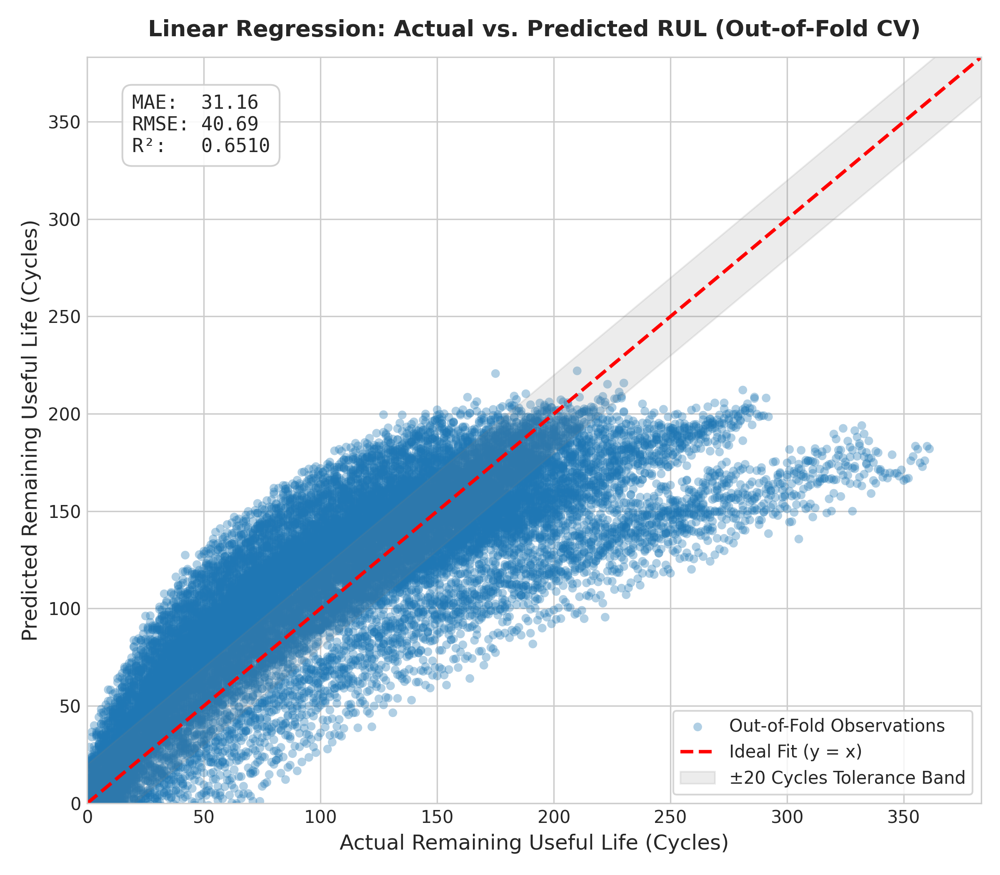

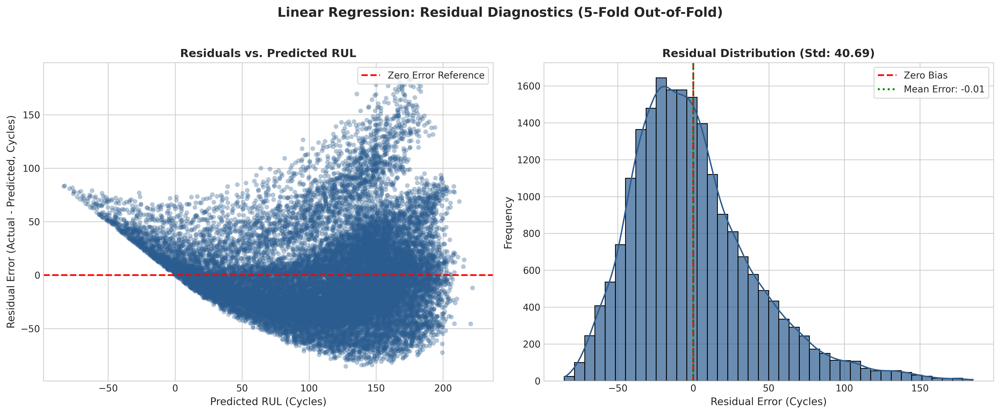

In [3]:
# Display diagnostic plots for Linear Regression
print("--- Actual vs. Predicted & Residual Diagnostics (Linear Regression) ---")
display(Image(filename=str(lr_rep_dir / "actual_vs_predicted.png")))
display(Image(filename=str(lr_rep_dir / "residual_plot.png")))

In [4]:
# Display Top Standardized Coefficients
lr_coefs = pd.read_csv(lr_rep_dir / "coefficients_summary.csv")
print("Top Feature Coefficients in Linear Regression (Standardized Features):")
display(lr_coefs.head(10))

Top Feature Coefficients in Linear Regression (Standardized Features):


,feature,coef_mean,coef_std
0,time_cycles,-27.500910,0.667001
1,sensor_11,-6.448017,0.294203
2,sensor_12,4.237594,0.314525
3,sensor_4,-4.050326,0.241563
4,sensor_7,3.727388,0.365880
5,sensor_9,-3.657803,0.817167
6,sensor_15,-3.014054,0.429009
7,sensor_2,-2.669491,0.216407
8,sensor_21,2.646154,0.313054
9,sensor_14,-2.572404,1.298584


---
## 2. Random Forest Regressor (Ensemble of Decision Trees)

Random Forest constructs an ensemble of de-correlated decision trees:
- `n_estimators = 200`
- `max_depth = None`
- `min_samples_split = 2`
- `min_samples_leaf = 1`
- Original unscaled numerical features.

In [5]:
rf_rep_dir = project_root / "reports" / "individual_models" / "random_forest"

rf_metrics_df = pd.read_csv(rf_rep_dir / "fold_metrics.csv")
with open(rf_rep_dir / "summary_metrics.json", "r") as f:
    rf_summary = json.load(f)

print("=== RANDOM FOREST: 5-FOLD CROSS-VALIDATION RESULTS ===")
display(rf_metrics_df)

print(f"\n5-Fold Mean MAE  : {rf_summary['mean_MAE']:.2f} ± {rf_summary['std_MAE']:.2f} cycles")
print(f"5-Fold Mean RMSE : {rf_summary['mean_RMSE']:.2f} ± {rf_summary['std_RMSE']:.2f} cycles")
print(f"5-Fold Mean R²   : {rf_summary['mean_R2']:.4f} ± {rf_summary['std_R2']:.4f}")

=== RANDOM FOREST: 5-FOLD CROSS-VALIDATION RESULTS ===


,MAE,RMSE,R2,Fold,Train_Engines,Val_Engines,Val_Rows
0,26.762595,40.360433,0.674975,Fold 1,80,20,4120
1,25.737855,37.975986,0.699457,Fold 2,80,20,4133
2,28.619167,39.045314,0.679309,Fold 3,80,20,4126
3,25.816524,36.533271,0.710960,Fold 4,80,20,4125
4,27.341577,36.575126,0.705292,Fold 5,80,20,4127



5-Fold Mean MAE  : 26.86 ± 1.19 cycles
5-Fold Mean RMSE : 38.10 ± 1.64 cycles
5-Fold Mean R²   : 0.6940 ± 0.0160


--- Actual vs. Predicted & Residual Diagnostics (Random Forest) ---


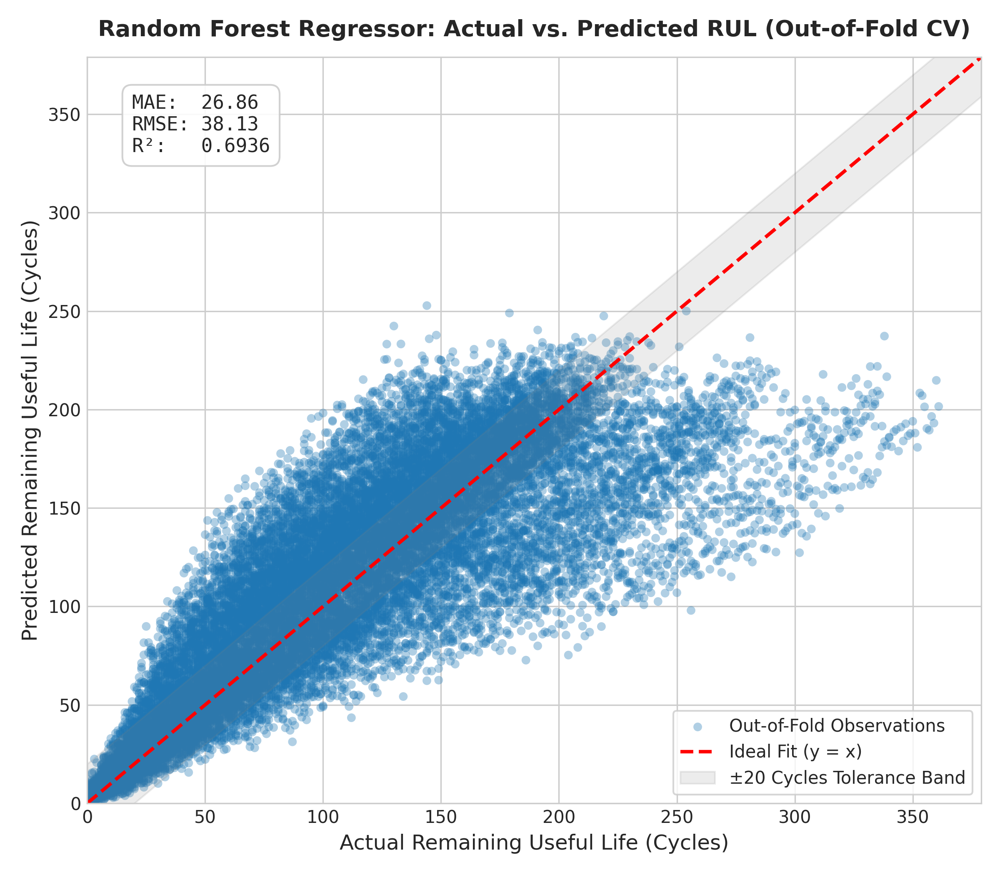

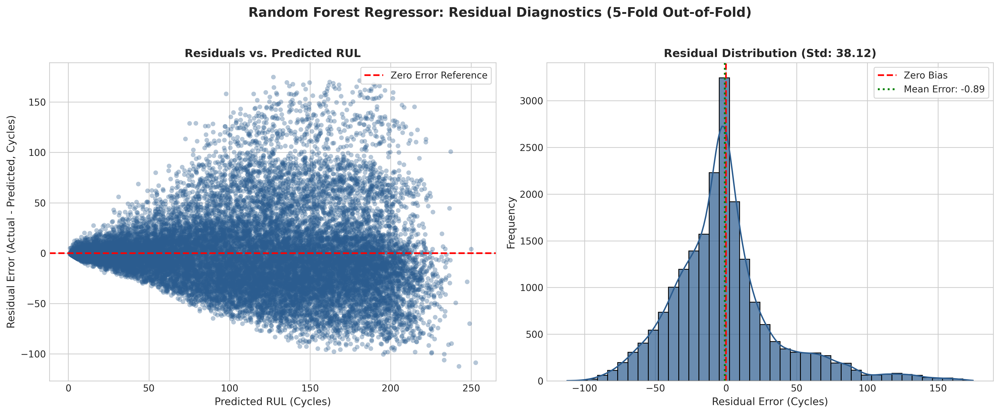

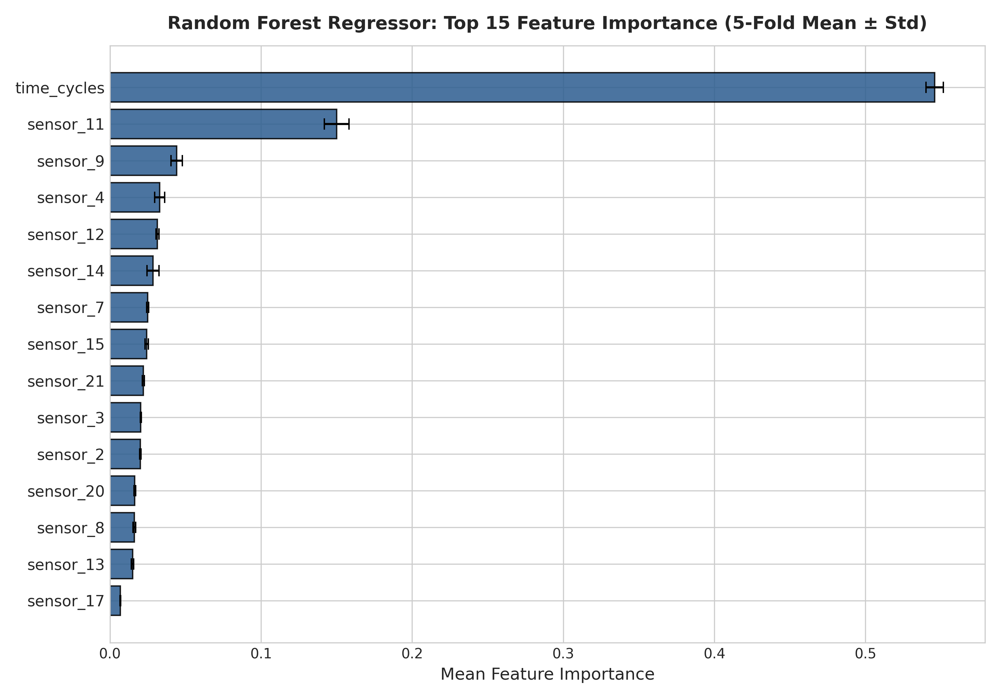

In [6]:
print("--- Actual vs. Predicted & Residual Diagnostics (Random Forest) ---")
display(Image(filename=str(rf_rep_dir / "actual_vs_predicted.png")))
display(Image(filename=str(rf_rep_dir / "residual_plot.png")))
display(Image(filename=str(rf_rep_dir / "feature_importance.png")))

In [7]:
rf_imp_df = pd.read_csv(rf_rep_dir / "feature_importance.csv")
print("Random Forest Top 10 Features by Impurity Reduction:")
display(rf_imp_df.head(10))

Random Forest Top 10 Features by Impurity Reduction:


,feature,importance_mean,importance_std
0,time_cycles,0.545803,0.005717
1,sensor_11,0.150027,0.008153
2,sensor_9,0.044241,0.003728
3,sensor_4,0.032912,0.003340
4,sensor_12,0.031504,0.001030
5,sensor_14,0.028589,0.003940
6,sensor_7,0.025089,0.000688
7,sensor_15,0.024363,0.001061
8,sensor_21,0.022168,0.000702
9,sensor_3,0.020481,0.000315


---
## 3. XGBoost Regressor (Gradient Boosted Decision Trees)

XGBoost sequentially fits shallow trees on the negative gradient of the mean squared error loss:
- `n_estimators = 300`
- `max_depth = 4`
- `learning_rate = 0.05`
- `subsample = 0.8`
- `colsample_bytree = 0.8`
- Original unscaled numerical features.

In [8]:
xgb_rep_dir = project_root / "reports" / "individual_models" / "xgboost"

xgb_metrics_df = pd.read_csv(xgb_rep_dir / "fold_metrics.csv")
with open(xgb_rep_dir / "summary_metrics.json", "r") as f:
    xgb_summary = json.load(f)

print("=== XGBOOST: 5-FOLD CROSS-VALIDATION RESULTS ===")
display(xgb_metrics_df)

print(f"\n5-Fold Mean MAE  : {xgb_summary['mean_MAE']:.2f} ± {xgb_summary['std_MAE']:.2f} cycles")
print(f"5-Fold Mean RMSE : {xgb_summary['mean_RMSE']:.2f} ± {xgb_summary['std_RMSE']:.2f} cycles")
print(f"5-Fold Mean R²   : {xgb_summary['mean_R2']:.4f} ± {xgb_summary['std_R2']:.4f}")

=== XGBOOST: 5-FOLD CROSS-VALIDATION RESULTS ===


,MAE,RMSE,R2,Fold,Train_Engines,Val_Engines,Val_Rows
0,26.740059,40.161793,0.678167,Fold 1,80,20,4120
1,25.266233,37.193176,0.711720,Fold 2,80,20,4133
2,28.242765,38.382504,0.690104,Fold 3,80,20,4126
3,25.656712,36.474934,0.711883,Fold 4,80,20,4125
4,27.171045,36.255444,0.710421,Fold 5,80,20,4127



5-Fold Mean MAE  : 26.62 ± 1.19 cycles
5-Fold Mean RMSE : 37.69 ± 1.61 cycles
5-Fold Mean R²   : 0.7005 ± 0.0155


--- Actual vs. Predicted & Residual Diagnostics (XGBoost) ---


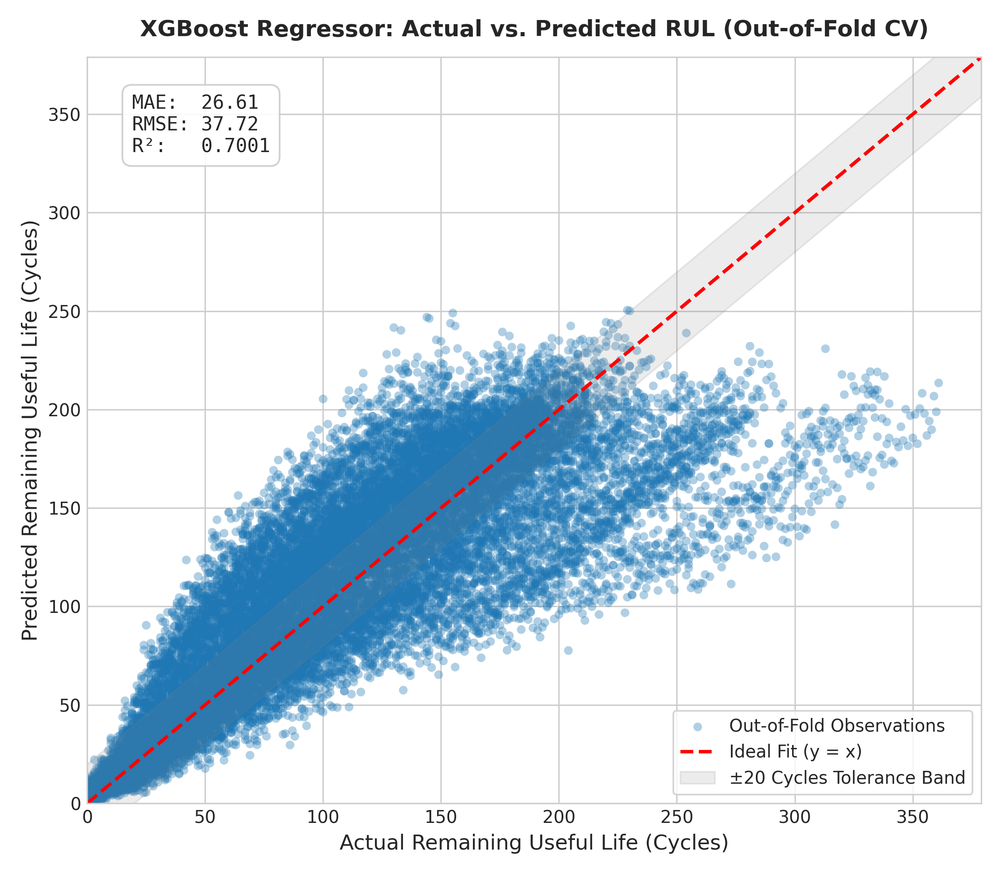

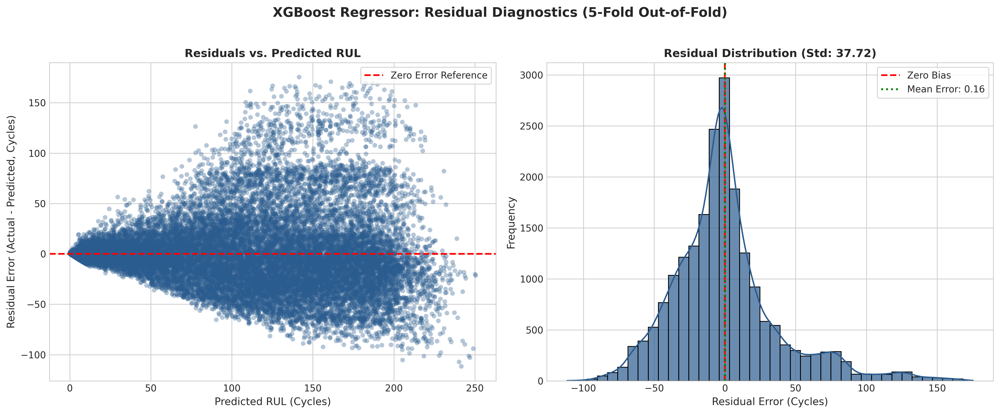

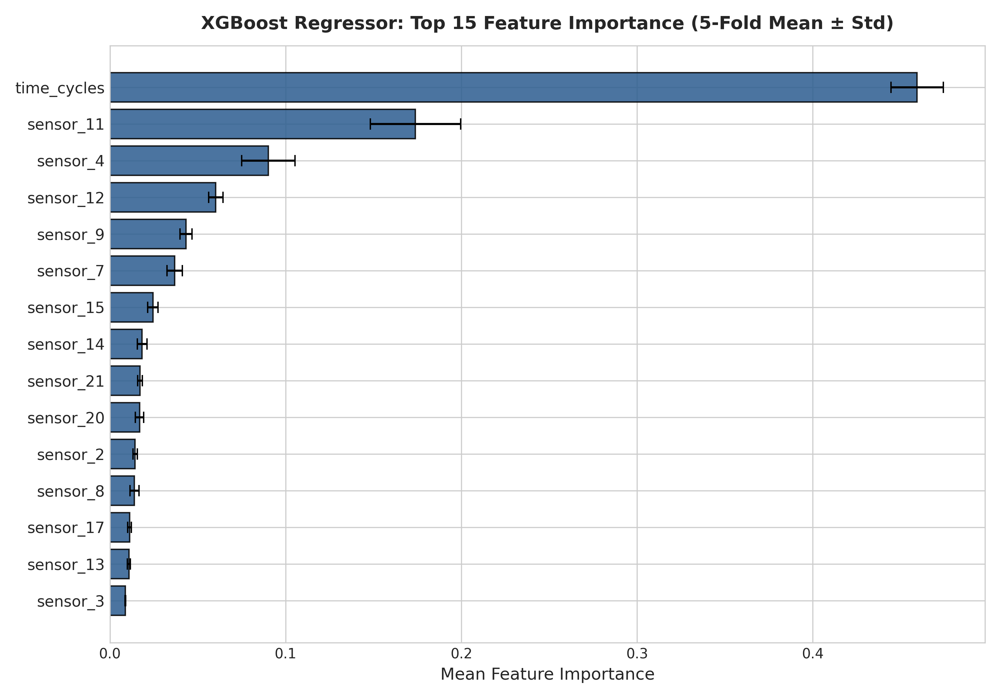

In [9]:
print("--- Actual vs. Predicted & Residual Diagnostics (XGBoost) ---")
display(Image(filename=str(xgb_rep_dir / "actual_vs_predicted.png")))
display(Image(filename=str(xgb_rep_dir / "residual_plot.png")))
display(Image(filename=str(xgb_rep_dir / "feature_importance.png")))

In [10]:
xgb_imp_df = pd.read_csv(xgb_rep_dir / "feature_importance.csv")
print("XGBoost Top 10 Features by Average Gain:")
display(xgb_imp_df.head(10))

XGBoost Top 10 Features by Average Gain:


,feature,importance_mean,importance_std
0,time_cycles,0.459362,0.014933
1,sensor_11,0.173887,0.025740
2,sensor_4,0.090172,0.015250
3,sensor_12,0.060302,0.004065
4,sensor_9,0.043347,0.003356
5,sensor_7,0.036841,0.004361
6,sensor_15,0.024465,0.002877
7,sensor_14,0.018353,0.002754
8,sensor_21,0.017190,0.001347
9,sensor_20,0.016930,0.002376


---
## 4. Multi-Model Benchmark Comparison

Let us compare the 5-fold cross-validation performance across all three individual models.

In [11]:
comparative_df = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE (Cycles)": f"{lr_summary['mean_MAE']:.2f} ± {lr_summary['std_MAE']:.2f}",
        "RMSE (Cycles)": f"{lr_summary['mean_RMSE']:.2f} ± {lr_summary['std_RMSE']:.2f}",
        "R² Score": f"{lr_summary['mean_R2']:.4f} ± {lr_summary['std_R2']:.4f}",
        "Features Preprocessing": "StandardScaler (fitted strictly on train fold)"
    },
    {
        "Model": "Random Forest",
        "MAE (Cycles)": f"{rf_summary['mean_MAE']:.2f} ± {rf_summary['std_MAE']:.2f}",
        "RMSE (Cycles)": f"{rf_summary['mean_RMSE']:.2f} ± {rf_summary['std_RMSE']:.2f}",
        "R² Score": f"{rf_summary['mean_R2']:.4f} ± {rf_summary['std_R2']:.4f}",
        "Features Preprocessing": "Original unscaled numerical features"
    },
    {
        "Model": "XGBoost",
        "MAE (Cycles)": f"{xgb_summary['mean_MAE']:.2f} ± {xgb_summary['std_MAE']:.2f}",
        "RMSE (Cycles)": f"{xgb_summary['mean_RMSE']:.2f} ± {xgb_summary['std_RMSE']:.2f}",
        "R² Score": f"{xgb_summary['mean_R2']:.4f} ± {xgb_summary['std_R2']:.4f}",
        "Features Preprocessing": "Original unscaled numerical features"
    }
])

print("=" * 90)
print("             INDIVIDUAL MODEL BENCHMARK SUMMARY (5-FOLD GROUPKFOLD CV)")
print("=" * 90)
display(comparative_df)

             INDIVIDUAL MODEL BENCHMARK SUMMARY (5-FOLD GROUPKFOLD CV)


,Model,MAE (Cycles),RMSE (Cycles),R² Score,Features Preprocessing
0,Linear Regression,31.16 ± 2.35,40.55 ± 3.85,0.6524 ± 0.0531,StandardScaler (fitted strictly on train fold)
1,Random Forest,26.86 ± 1.19,38.10 ± 1.64,0.6940 ± 0.0160,Original unscaled numerical features
2,XGBoost,26.62 ± 1.19,37.69 ± 1.61,0.7005 ± 0.0155,Original unscaled numerical features


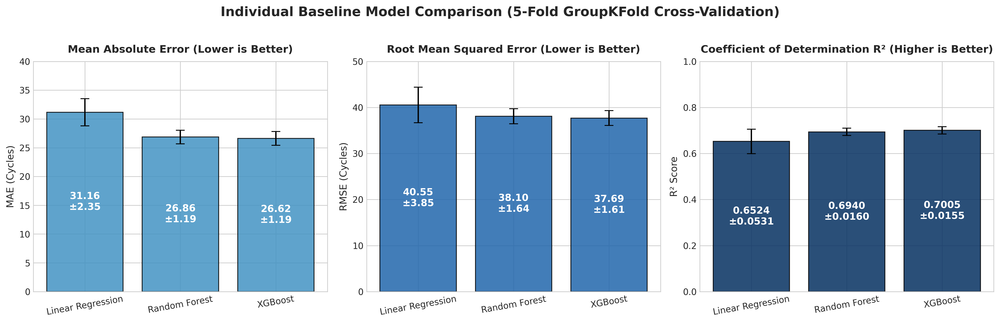

In [12]:
# Display comparative bar charts
display(Image(filename=str(project_root / "reports" / "individual_models" / "model_comparison.png")))

---
## 5. Engineering Analysis & Discussion

### 1. Why Tree-Based Models Outperform Linear Regression
- **Non-Linear Degradation Knee**: As revealed during EDA, turbofan engine wear is not a uniform straight line from cycle 0 to failure. Turbomachinery operates stably for the first 80–100 cycles before accelerated wear takes over. A linear model is forced to compromise a single slope through both regimes, resulting in an $R^2$ of ~0.65.
- **Recursive Partitioning**: Both Random Forest ($R^2 \approx 0.694$) and XGBoost ($R^2 \approx 0.701$) successfully segment the operational space into distinct piecewise constant/linear zones, capturing the non-linear inflection point without requiring manual piecewise splitting.

### 2. Feature Importance Consensus
Across both Random Forest and XGBoost:
- **`time_cycles`**: Consistently ranks as the single most dominant predictive driver, as cumulative runtime directly governs wear progression.
- **Physical Sensors**: `sensor_11` (HPC static pressure), `sensor_9` (Physical core speed), `sensor_4` (LPT outlet temperature), and `sensor_12` (Ratio of fuel flow to Ps30) emerge as the leading thermodynamic wear indicators.

### 3. Residual Diagnostics & Asymmetric Error Properties
- **Heteroscedasticity**: Across all three models, prediction variance is widest at high true RUL ($RUL > 125$), where sensor readings are virtually identical to nominal healthy baseline levels.
- **Convergence Near Failure**: As true RUL approaches zero ($RUL < 50$), prediction error shrinks significantly and tightly tracks the diagonal. In aviation maintenance, high precision in late-stage degradation is exactly what is required to schedule maintenance safely and avoid in-flight engine shutdowns.

*Next Steps: We are now positioned to explore ensembling (Averaging, Weighted, Stacking) and advanced temporal feature engineering (rolling means, rolling standard deviations) to further improve prognostic accuracy.*